# 04 · Aplicación Genérica del Análisis de Cuellos de Botella
### Cómo aplicar `analisis_cuellos_botella.py` a cualquier dataset de fabricación

Este notebook demuestra cómo utilizar el módulo universal `analisis_cuellos_botella.py` sobre:
1. **El dataset real del Reto LOSSIA (HORSE Línea 5)**.
2. **Un dataset completamente nuevo y distinto** (con nombres de columna arbitrarios, diferentes turnos y umbrales).

---

### ¿Por qué este enfoque es genérico y extrapolable?
1. **Inferencia automática de columnas**: Detecta por sinónimos columnas como `TBF`/`uptime`, `TAP`/`downtime`, `DES`/`starvation`, `SAT`/`blocking`, etc.
2. **Detección automática de líneas en paralelo**: Identifica puestos contiguos que se reparten la cadencia (50% de volumen).
3. **Filtro de anomalías de sensor (chattering)**: Distingue averías mecánicas reales de falsos positivos en fotocélulas o finales de carrera.
4. **Parámetros de planta configurables**: Horas de turno (`t_abierto_dia`), disponibilidad objetivo (`dp_min_target`), tiempo de ciclo (`tcy_max_cmin`), y pesos del índice IPL.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Importamos la clase principal de nuestro módulo genérico
from analisis_cuellos_botella import BottleneckAnalyzer

print("Módulo analisis_cuellos_botella importado correctamente.")


Módulo analisis_cuellos_botella importado correctamente.


## Caso 1: Aplicación directa sobre los datos del Reto HORSE
Solo requerimos instanciar la clase y llamar a `fit_transform()`. El script resuelve automáticamente las columnas, agrupa los días y calcula el IPL.


In [8]:
# 1. Cargar datos
df_horse = pd.read_csv("Datos_limpios/datos_limpios.csv")
cfg_horse = pd.read_csv("Datos_limpios/config_limpia.csv")

# 2. Inicializar analizador con los parámetros de la planta de Valladolid
analizador_horse = BottleneckAnalyzer(
    t_abierto_dia=22.0,      # 22 horas abiertas al día
    dp_min_target=90.0,      # Disponibilidad contractual ≥ 90%
    tcy_max_cmin=80.0,       # Tiempo de ciclo límite ≤ 80 cmin (48 s)
    auto_detect_parallel=True
)

# 3. Ejecutar análisis completo
resultados_horse = analizador_horse.fit_transform(df_horse, config_df=cfg_horse)

print(f"Análisis completado para {len(resultados_horse)} operaciones.")
display(analizador_horse.get_top_penalizantes(5))


Análisis completado para 85 operaciones.


,Orden_OP,Operacion,Tipo,IPL,TAP,TAI,Dp,Tcy_linea_cmin,Fpm,MTTR_min,Impacto_Vecinas,Diagnostico_Tipo
0,88,Ma_BM2_2,Manutención / auxiliar,78.337508,9.850000,7.260000,33.126828,19.630375,213.687034,1.854481,2.608125,Cuello de Botella Crítico (Penalizante Muy Alta)
1,75,ST-2390,Estación (ST),53.261960,4.266250,2.562500,77.298120,56.956380,393.318085,0.425296,3.817538,Penalizante Moderada
2,20,ST-0260,Estación (ST),46.540782,0.681250,2.271250,95.732847,59.351968,40.451438,0.654000,10.922500,Penalizante Moderada
3,37,PM-2020,Puesto manual (PM),40.590413,0.733750,0.369375,96.432148,77.683205,33.907296,0.847653,4.330625,Penalizante Moderada
4,63,PM2250,Puesto manual (PM),40.327606,2.914375,1.575625,85.033376,64.653868,15.415277,7.382058,1.694375,Penalizante Moderada


### Visualización automática del informe HORSE y Cuello de Botella Medio


INFORME EJECUTIVO DE CUELLOS DE BOTELLA Y MÁQUINAS PENALIZANTES
• Total operaciones analizadas: 85
• Referencias contractuales aplicadas: Dp ≥ 90.0% | Tcy ≤ 80.0 cmin
• Operaciones que incumplen Disponibilidad Propia (Dp < 90.0%): 6
• Operaciones con Tiempo de Ciclo lento (Tcy > 80.0 cmin): 5
---------------------------------------------------------------------------
🏆 TOP 5 MÁQUINAS MÁS PENALIZANTES (Mantenimiento Prioritario):
---------------------------------------------------------------------------
#1 | Puesto #88: Ma_BM2_2 (Manutención / auxiliar) → IPL: 78.3/100 | TAP: 9.85 h/d | Dp: 33.1% | Impacto Vecinas: 2.61 h
#2 | Puesto #75: ST-2390 (Estación (ST)) → IPL: 53.3/100 | TAP: 4.27 h/d | Dp: 77.3% | Impacto Vecinas: 3.82 h
#3 | Puesto #20: ST-0260 (Estación (ST)) → IPL: 46.5/100 | TAP: 0.68 h/d | Dp: 95.7% | Impacto Vecinas: 10.92 h
#4 | Puesto #37: PM-2020 (Puesto manual (PM)) → IPL: 40.6/100 | TAP: 0.73 h/d | Dp: 96.4% | Impacto Vecinas: 4.33 h
#5 | Puesto #63: PM2250 (Puesto

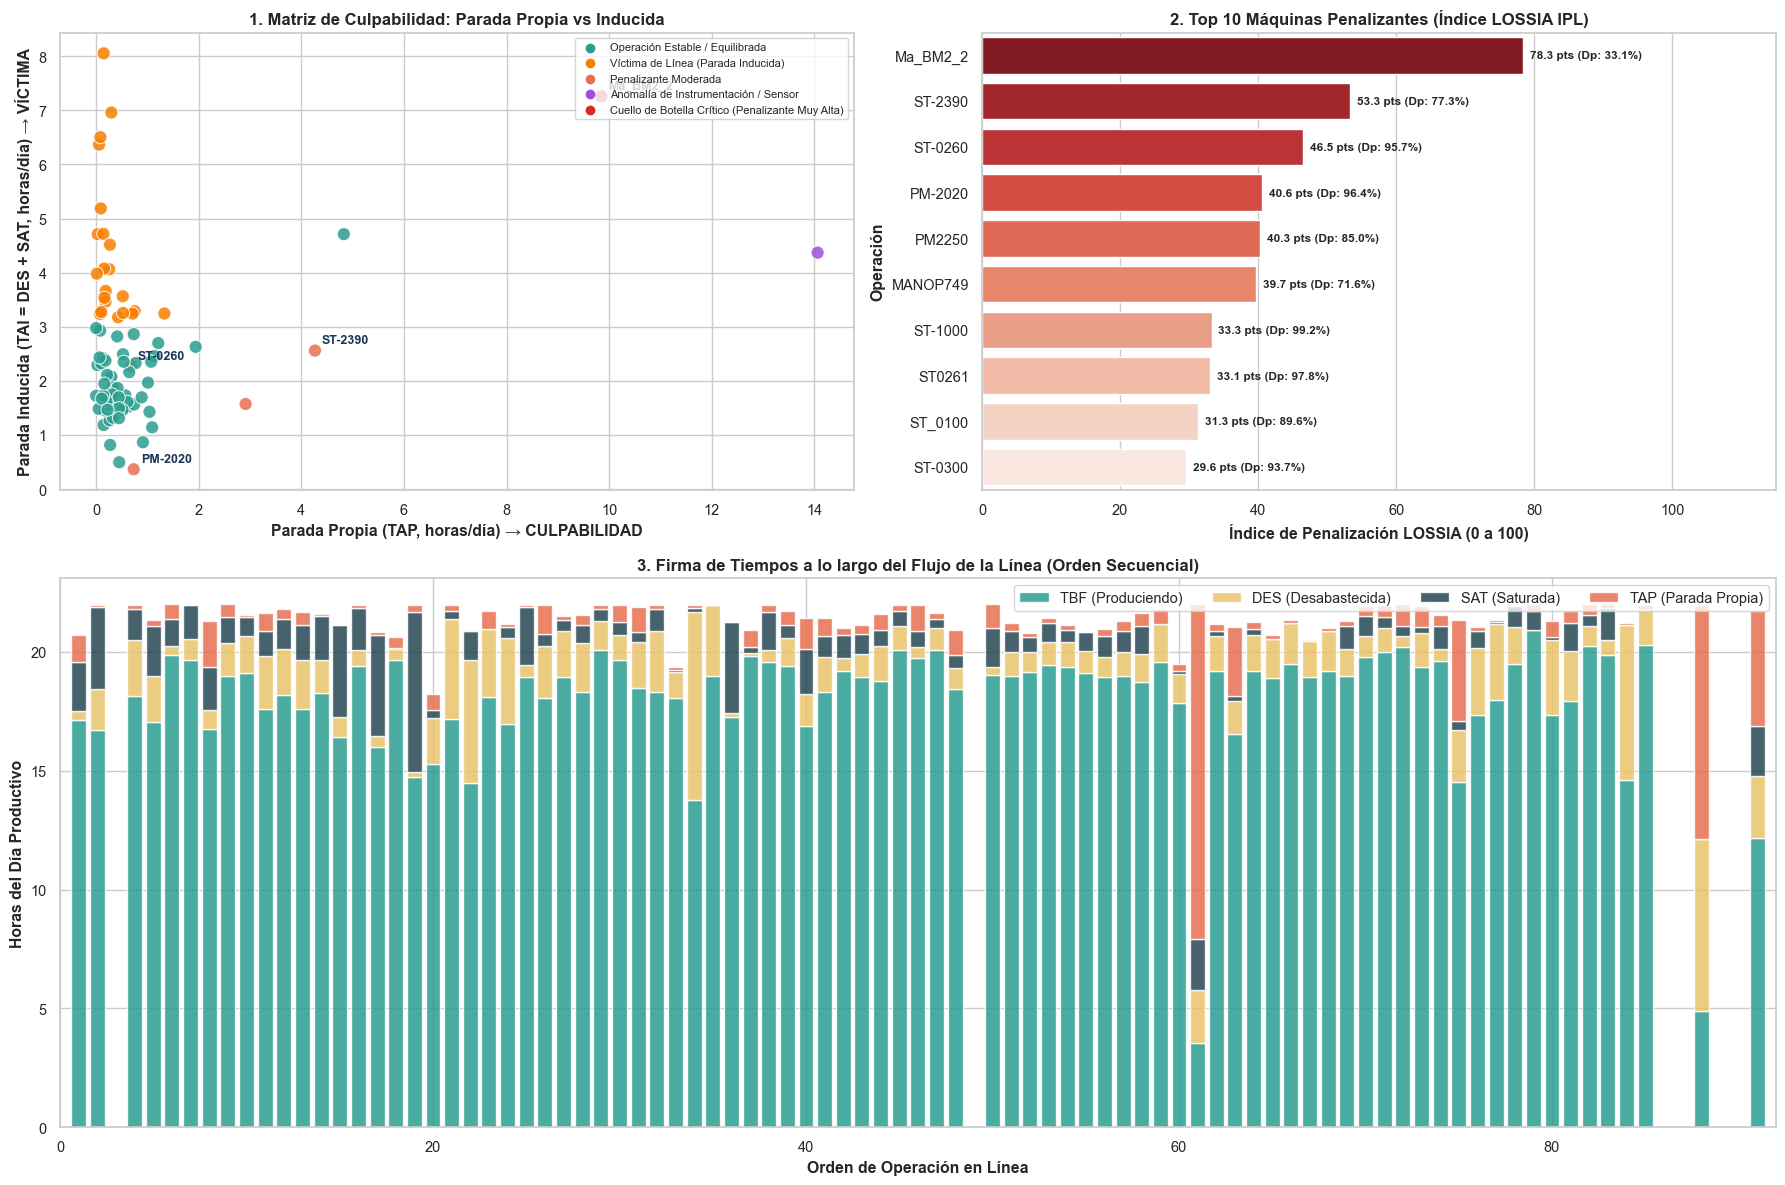

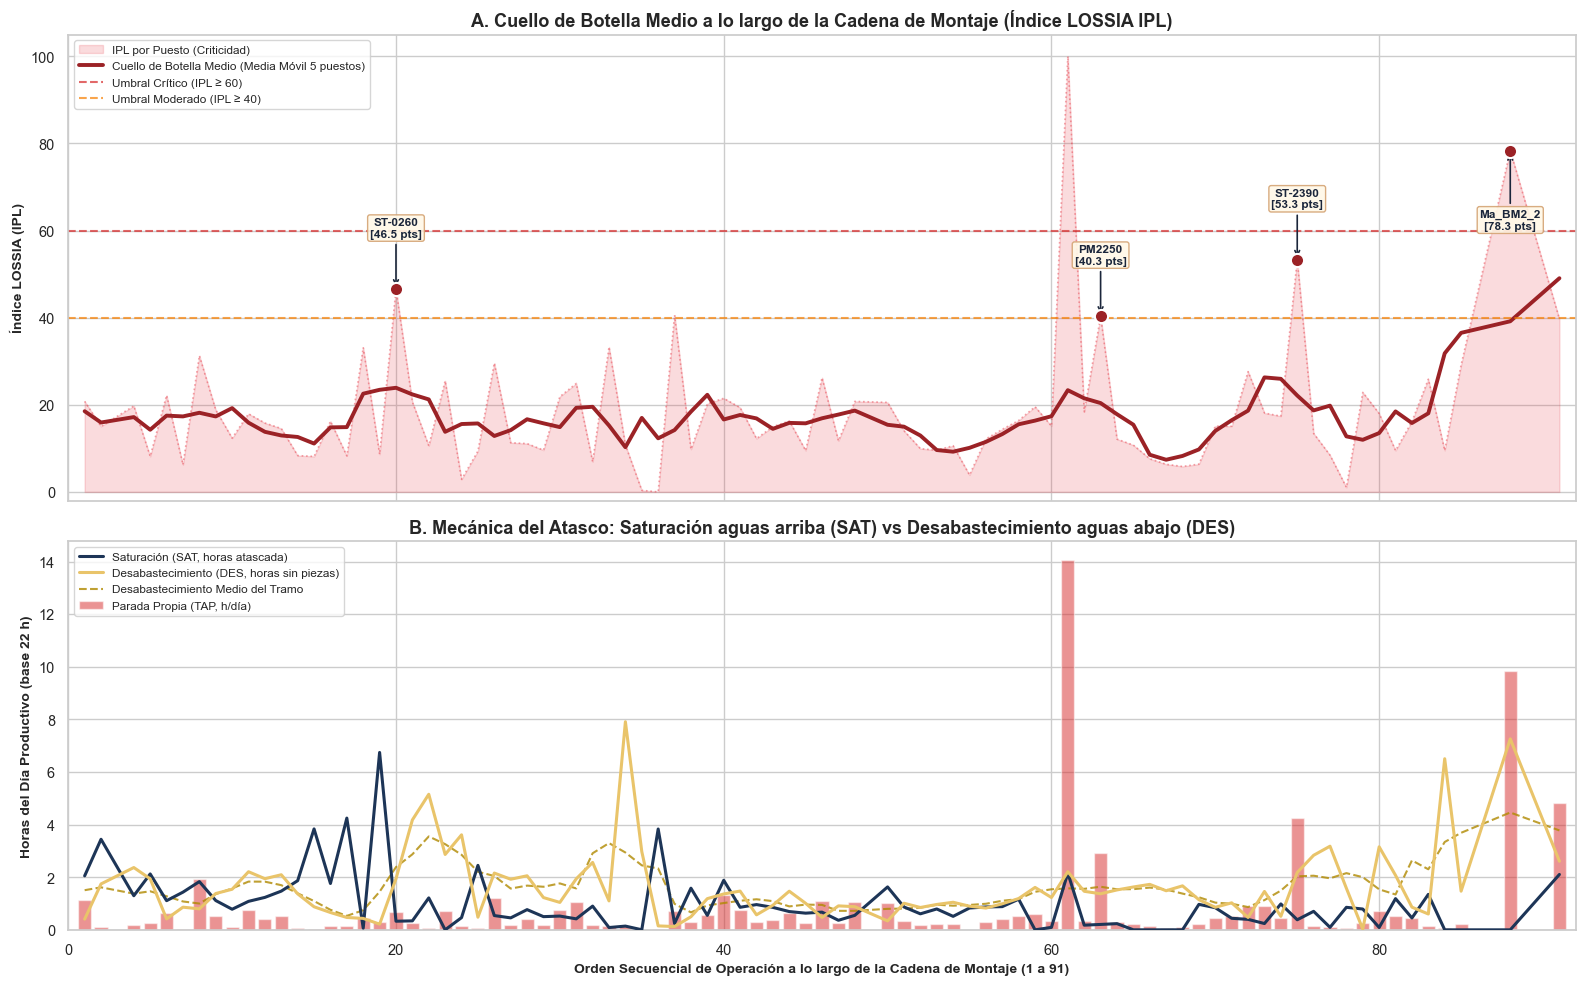

In [9]:
# Imprime el informe ejecutivo en texto plano listo para enviar a jefatura
print(analizador_horse.generar_informe_texto())

# 1. Panel general de tres cuadrantes
analizador_horse.plot_resumen()

# 2. Código autocontenido para graficar el Cuello de Botella Medio a lo largo de la cadena
df_plot = analizador_horse.results_df.sort_values("Orden_OP").reset_index(drop=True)
ordenes = df_plot["Orden_OP"].values
ipl_vals = df_plot["IPL"].values
tap = df_plot["TAP"].values
sat = df_plot["SAT"].values
des = df_plot["DES"].values

# Curva de cuello de botella medio (media móvil de 5 puestos)
ipl_para_tendencia = df_plot["IPL"].copy()
if df_plot["es_anomalia_sensor"].any():
    ipl_para_tendencia[df_plot["es_anomalia_sensor"]] = np.nan
ipl_media_movil = ipl_para_tendencia.rolling(window=5, center=True, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})

# Panel 1: IPL y Cuello de Botella Medio
ax1.fill_between(ordenes, 0, ipl_vals, color="#E63946", alpha=0.18, label="IPL por Puesto (Criticidad)")
ax1.plot(ordenes, ipl_vals, color="#E63946", alpha=0.45, linewidth=1.2, linestyle=":")
ax1.plot(ordenes, ipl_media_movil, color="#9B2226", linewidth=2.8, label="Cuello de Botella Medio (Media Móvil 5 puestos)")
ax1.axhline(60, color="#D62828", linestyle="--", linewidth=1.5, alpha=0.7, label="Umbral Crítico (IPL ≥ 60)")
ax1.axhline(40, color="#F77F00", linestyle="--", linewidth=1.5, alpha=0.7, label="Umbral Moderado (IPL ≥ 40)")

# Puntos destacados
puntos_destacados = ["ST-0260", "PM2250", "ST-2390", "Ma_BM2_2"]
for op_name in puntos_destacados:
    r_pt = df_plot[df_plot.Operacion == op_name]
    if not r_pt.empty:
        x_pt = r_pt["Orden_OP"].values[0]
        y_pt = r_pt["IPL"].values[0]
        ax1.scatter(x_pt, y_pt, color="#9B2226", s=90, zorder=5, edgecolor="white", linewidth=1.5)
        offset_y = 12 if y_pt < 70 else -18
        ax1.annotate(
            f"{op_name}\n[{y_pt:.1f} pts]",
            xy=(x_pt, y_pt), xytext=(x_pt, y_pt + offset_y),
            ha="center", fontsize=8.5, weight="bold", color="#1B263B",
            arrowprops=dict(arrowstyle="->", color="#1B263B", lw=1.2),
            bbox=dict(boxstyle="round,pad=0.2", facecolor="#FFF8E7", edgecolor="#D4A373", alpha=0.9)
        )

ax1.set_title("A. Cuello de Botella Medio a lo largo de la Cadena de Montaje (Índice LOSSIA IPL)", fontsize=13, weight="bold")
ax1.set_ylabel("Índice LOSSIA (IPL)", fontsize=10, weight="bold")
ax1.set_ylim(-2, 105)
ax1.legend(loc="upper left", frameon=True, fontsize=8.5)

# Panel 2: Mecánica de Flujo (SAT vs TAP vs DES)
ax2.bar(ordenes, tap, width=0.8, color="#D62828", alpha=0.5, label="Parada Propia (TAP, h/día)", zorder=2)
ax2.plot(ordenes, sat, color="#1D3557", linewidth=2.2, label="Saturación (SAT, horas atascada)", zorder=3)
ax2.plot(ordenes, des, color="#E9C46A", linewidth=2.2, label="Desabastecimiento (DES, horas sin piezas)", zorder=3)
des_media = pd.Series(des).rolling(5, center=True, min_periods=1).mean()
ax2.plot(ordenes, des_media, color="#B08900", linestyle="--", linewidth=1.5, alpha=0.8, label="Desabastecimiento Medio del Tramo")

ax2.set_title("B. Mecánica del Atasco: Saturación aguas arriba (SAT) vs Desabastecimiento aguas abajo (DES)", fontsize=13, weight="bold")
ax2.set_xlabel("Orden Secuencial de Operación a lo largo de la Cadena de Montaje (1 a 91)", fontsize=10, weight="bold")
ax2.set_ylabel("Horas del Día Productivo (base 22 h)", fontsize=10, weight="bold")
ax2.set_xlim(ordenes.min() - 1, ordenes.max() + 1)
ax2.legend(loc="upper left", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.savefig("cuello_botella_cadena_montaje.png", dpi=160, bbox_inches="tight")
plt.show()
